<a href="https://colab.research.google.com/github/vedrode2011-collab/TFIM-trotter-experiment/blob/main/ZX_Reduction_TFIM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Setting up account


In [1]:
!pip install qiskit qiskit-ibm-runtime

In [2]:
from qiskit_ibm_runtime import QiskitRuntimeService

QiskitRuntimeService.save_account(
    token="PjKgjVYum4l7n31ZdAknhRaYIEeVHb5ZlorhlpZTVYaq",
    instance="crn:v1:bluemix:public:quantum-computing:us-east:a/127e1f82f8f24dfc857d31616b76107b:97bb2674-daaf-4b07-bfe3-541a9d43f593::",
    overwrite=True,
)

# TFIM Trotter Circuit: ZX-Calculus Reduction, Equivalence Checking, and Noisy-Hardware Magnetization Accuracy Comparison

In [3]:
!pip install qiskit qiskit_aer qiskit-ibm-runtime pyzx pylatexenc

In [4]:
import numpy as np
from datetime import datetime

import matplotlib.pyplot as plt
import pyzx as zx
from qiskit import QuantumCircuit, qasm2
from qiskit.quantum_info import Operator, Statevector, Pauli
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
from qiskit_ibm_runtime.fake_provider import FakeKingston
from qiskit.visualization import plot_histogram
from IPython.display import display

## 1. Build the TFIM Trotter circuit (baseline)

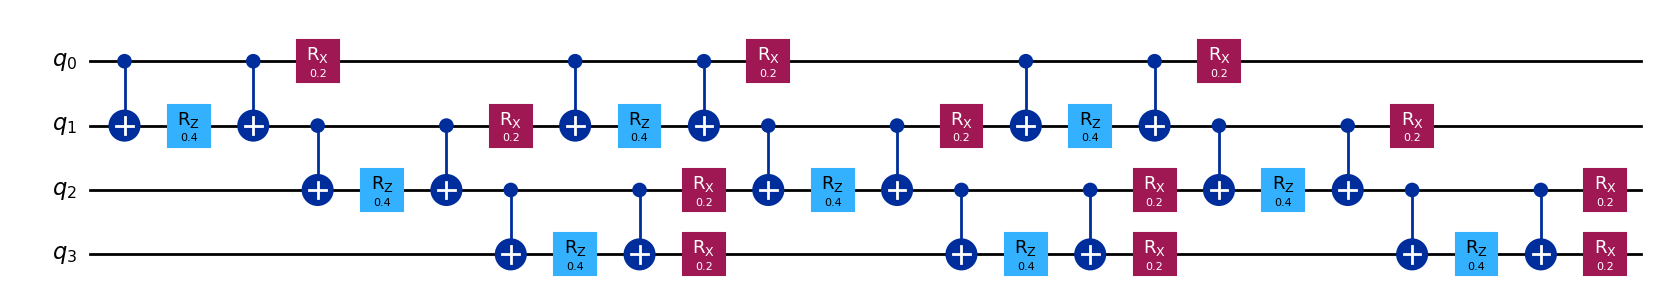

In [5]:
num_qubits = 4
J = 1.0
g = 0.5
dt = 0.2          # small Trotter time step
steps = 3         # repetition amount

def build_tfim_trotter_circuit(num_qubits, J, g, dt, steps):
    qc = QuantumCircuit(num_qubits)
    for _ in range(steps):
        # ZZ interaction layer
        for i in range(num_qubits - 1):
            qc.cx(i, i + 1)
            qc.rz(2 * J * dt, i + 1)
            qc.cx(i, i + 1)
        # Transverse field layer
        for i in range(num_qubits):
            qc.rx(2 * g * dt, i)
    return qc

qc_baseline = build_tfim_trotter_circuit(num_qubits, J, g, dt, steps)
qc_baseline.draw("mpl")

## 2. Reduction functions

Each function does: `qc -> qasm -> pyzx graph -> reduce -> extract -> qasm -> qc`,
then checks equivalence against the baseline circuit before returning.
Raises immediately if the check fails.

The extractor differs by reduction type:
- `teleport_reduce` leaves the graph CIRCUIT-LIKE, so it converts back directly via `zx.Circuit.from_graph()`.
- `full_reduce` changes the graph into a general GRAPH-LIKE ZX-diagram (only green spiders plus Hadamard edges),
  which requires the special `zx.extract_circuit()` method to convert back into a circuit.

Using the wrong one raises an error.

In [6]:
"""
def circuits_equivalent(qc1, qc2):
    sv1 = Statevector.from_instruction(qc1)
    sv2 = Statevector.from_instruction(qc2)
    return sv1 == sv2
"""
# we can isted use the c1.verify_equality(c3)

def teleport_reduce_circuit(qc):
    qasm_str = qasm2.dumps(qc)
    zx_baseline = zx.Circuit.from_qasm(qasm_str)
    graph = zx_baseline.to_graph()
    zx.teleport_reduce(graph)
    extracted = zx.Circuit.from_graph(graph)

    if not zx_baseline.verify_equality(extracted):
        raise ValueError("teleport_reduce output is NOT equal to baseline circuit")

    qc_out = QuantumCircuit.from_qasm_str(extracted.to_qasm())
    return qc_out


def full_reduce_circuit(qc):
    qasm_str = qasm2.dumps(qc)
    zx_baseline = zx.Circuit.from_qasm(qasm_str)
    graph = zx_baseline.to_graph()
    zx.full_reduce(graph)
    extracted = zx.extract_circuit(graph.copy())

    if not zx_baseline.verify_equality(extracted):
        raise ValueError("full_reduce output is NOT equal to baseline circuit")

    qc_out = QuantumCircuit.from_qasm_str(extracted.to_qasm())
    return qc_out


# Run the two reductions, each checked against the baseline as it's produced
qc_careful = teleport_reduce_circuit(qc_baseline)
print("teleport_reduce: equivalence check passed.")

qc_aggressive = full_reduce_circuit(qc_baseline)
print("full_reduce: equivalence check passed.")

teleport_reduce: equivalence check passed.
full_reduce: equivalence check passed.


## 3. Pre-flight metrics (before running anything)\n\nTotal gates, two-qubit gates, T-count, depth — for all three versions.

In [7]:
def circuit_metrics(qc):
    ops = qc.count_ops()
    total_gates = sum(ops.values())
    two_qubit_gates = sum(v for k, v in ops.items() if k in ("cx", "cz", "swap", "ecr"))

    # T-count via the ZX-graph representation (counts non-Clifford phase spiders)
    qasm_str = qasm2.dumps(qc)
    graph = zx.Circuit.from_qasm(qasm_str).to_graph()
    tcount = zx.tcount(graph)

    return {
        "total_gates": total_gates,
        "two_qubit_gates": two_qubit_gates,
        "tcount": tcount,
        "depth": qc.depth(),
    }

versions = {
    "baseline": qc_baseline,
    "careful": qc_careful,
    "aggressive": qc_aggressive,
}

print("--- Pre-flight circuit metrics ---")
for name, circ in versions.items():
    m = circuit_metrics(circ)
    print(name, "total_gates=", m["total_gates"], "two_qubit_gates=", m["two_qubit_gates"],
          "tcount=", m["tcount"], "depth=", m["depth"])

--- Pre-flight circuit metrics ---
baseline total_gates= 39 two_qubit_gates= 18 tcount= 21 depth= 24
careful total_gates= 39 two_qubit_gates= 18 tcount= 21 depth= 24
aggressive total_gates= 89 two_qubit_gates= 36 tcount= 21 depth= 61


## 4. Backend setup

One switch controls everything downstream: `backend_mode` is either `"fake"` or `"real"`.
This replaces the old separate scratch section (which referenced an undefined `ManilaV2()`,
and was later pinned to the now-retired `ibm_manila`) with a single, consistent path.
The real backend is pinned by name to `ibm_kingston`
(not "least busy") so results stay directly comparable to `FakeKingston` run after run.

In [8]:
# Choose which backend to run on: "fake" or "real"
backend_mode = "fake"   # switch to "real" once validated

if backend_mode == "fake":
    backend = FakeKingston()
else:
    service = QiskitRuntimeService()
    backend = service.backend("ibm_kingston")   # pinned by name, not least_busy

print(f"Using backend: {backend.name} (mode={backend_mode})")

pm = generate_preset_pass_manager(optimization_level=1, backend=backend)

shots_per_run = 4000
num_repetitions = 3

Using backend: fake_kingston (mode=fake)


## 5. Reusable function: run a set of circuits on a given backend

Same code path for fake and real hardware. Each circuit (baseline, careful, aggressive)
is transpiled specifically for the target backend's native gate set — this is the
"different hardware speaks a different language" step — then run, with counts and
pre-flight metrics stored together.

In [9]:
def run_versions_on_backend(versions, backend, shots=4000):
    pm_local = generate_preset_pass_manager(optimization_level=1, backend=backend)
    sampler = Sampler(mode=backend)
    results = {}

    for name, circ in versions.items():
        circ_with_measurement = circ.copy()
        circ_with_measurement.measure_all()
        isa_circ = pm_local.run(circ_with_measurement)

        job = sampler.run([isa_circ], shots=shots)
        counts = job.result()[0].data.meas.get_counts()

        ops = isa_circ.count_ops()
        results[name] = {
            "counts": counts,
            "job_id": job.job_id(),
            "metrics": {
                "total_gates": sum(ops.values()),
                "two_qubit_gates": sum(v for k, v in ops.items() if k in ("cz", "cx", "ecr", "swap")),
                "depth": isa_circ.depth(),
            },

        }
    return results

## 6. Run baseline, careful, and aggressive on BOTH the fake and the real Kingston backend\n\nUsing the identical function for both, so the comparison is apples-to-apples.

In [10]:
fake_backend = FakeKingston()
fake_results = run_versions_on_backend(versions, fake_backend, shots=shots_per_run)

service = QiskitRuntimeService()
real_backend = service.backend("ibm_kingston")
#comment this ↓ out if you want to restore from Job ID's
#  real_results = run_versions_on_backend(versions, real_backend, shots=shots_per_run)

/tmp/ipykernel_1109/2501373909.py:3: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)


# To take from job ID


In [11]:
def retrieve_results_from_job_ids(job_ids, versions):
    service = QiskitRuntimeService()
    results = {}
    for name, jid in job_ids.items():
        job = service.job(jid)
        result = job.result()
        counts = result[0].data.meas.get_counts()
        results[name] = {
            "counts": counts,
            "metrics": circuit_metrics(versions[name]),
        }
    return results

In [12]:
saved_job_ids = {
    "baseline": "dani9678gn2s739mmcv0",
    "careful": "dani97o2fm4c73f48ic0",
    "aggressive": "dani99lr85ps73fe3dog",
}

real_results = retrieve_results_from_job_ids(saved_job_ids, versions)

## 7. Histograms: fake vs. real, for all three circuit versions

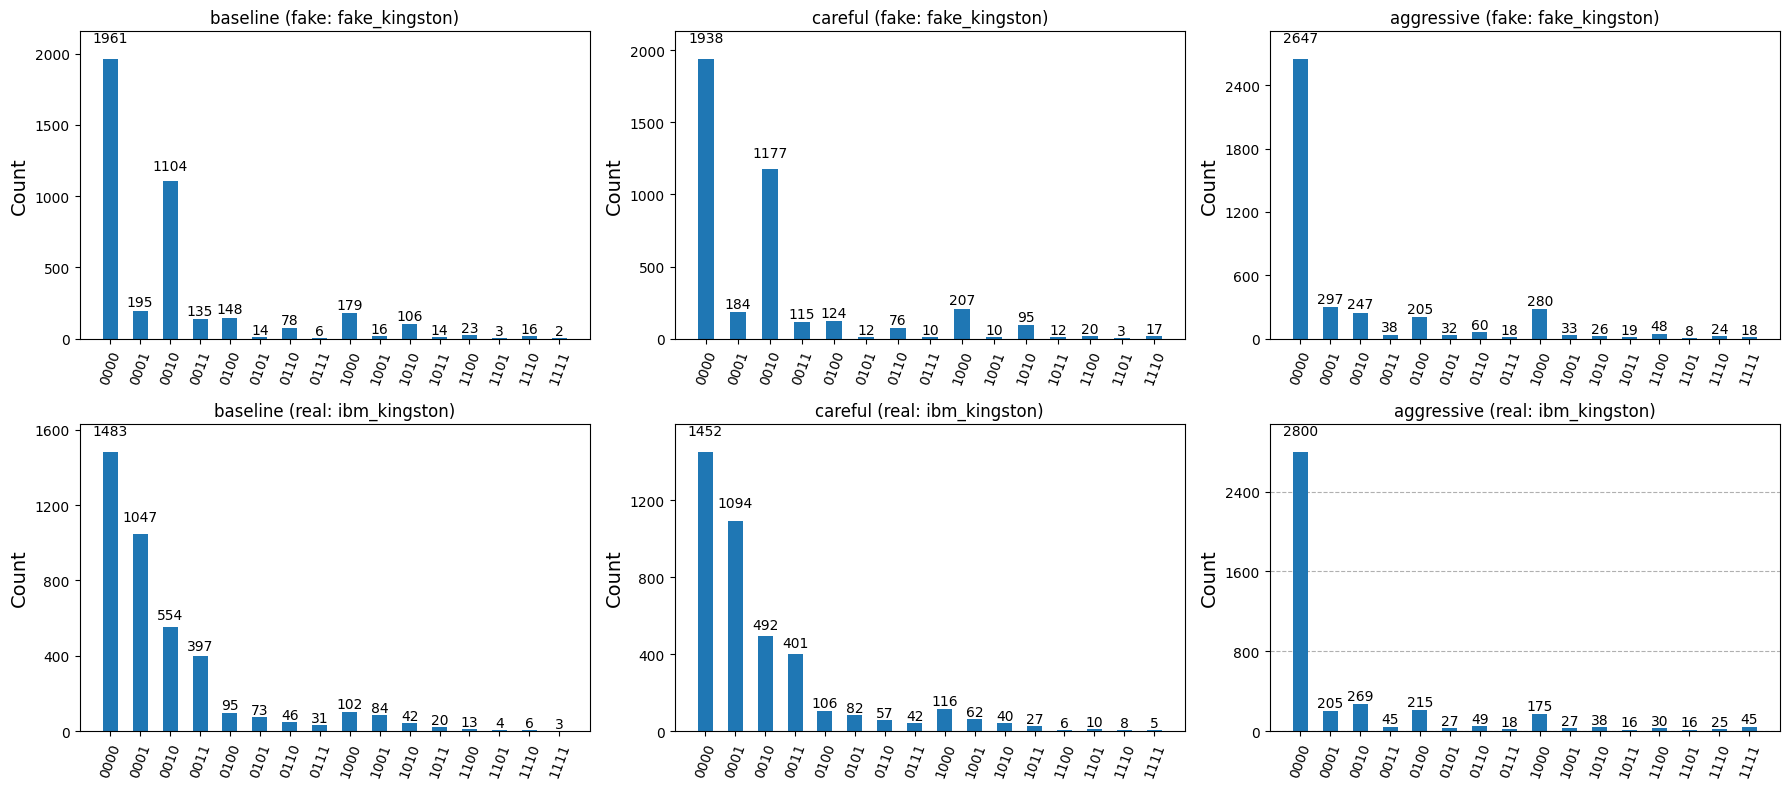

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8))

for col, (name, circ) in enumerate(versions.items()):
    plot_histogram(fake_results[name]["counts"], ax=axes[0][col])
    axes[0][col].set_title(f"{name} (fake: {fake_backend.name})")

    plot_histogram(real_results[name]["counts"], ax=axes[1][col])
    axes[1][col].set_title(f"{name} (real: {real_backend.name})")

plt.tight_layout()
plt.show()

## 8. The Circuits of all 3: Baseline, teleport_reduce, and full_reduce

Baseline circuit:


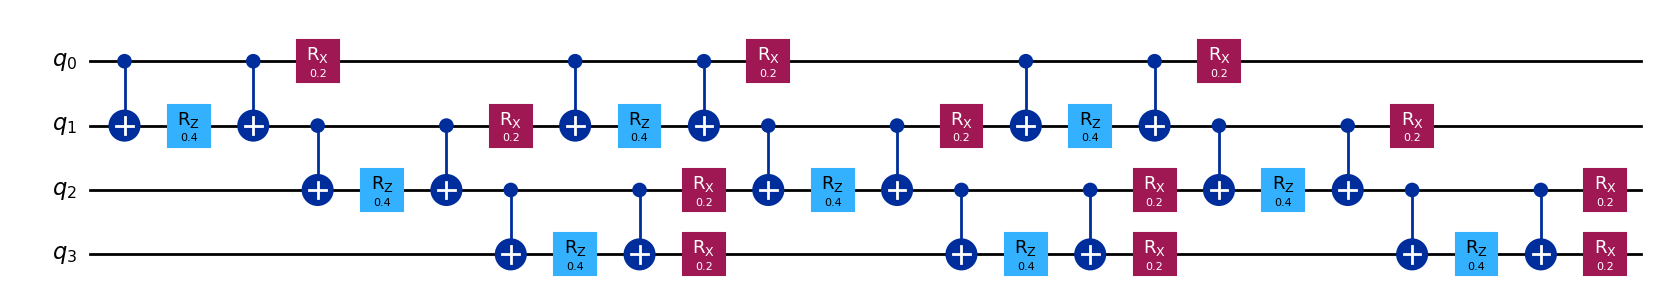

Careful (teleport_reduce) circuit:


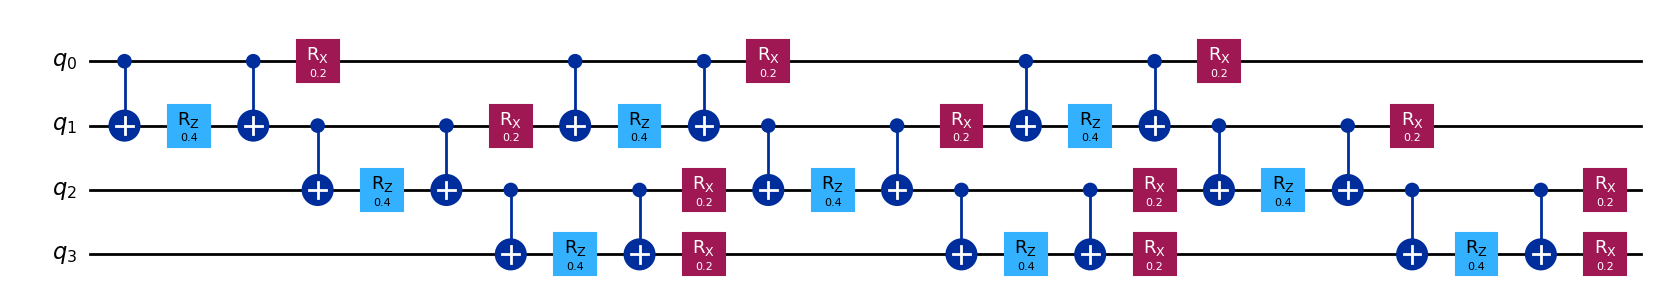

Aggressive (full_reduce) circuit:


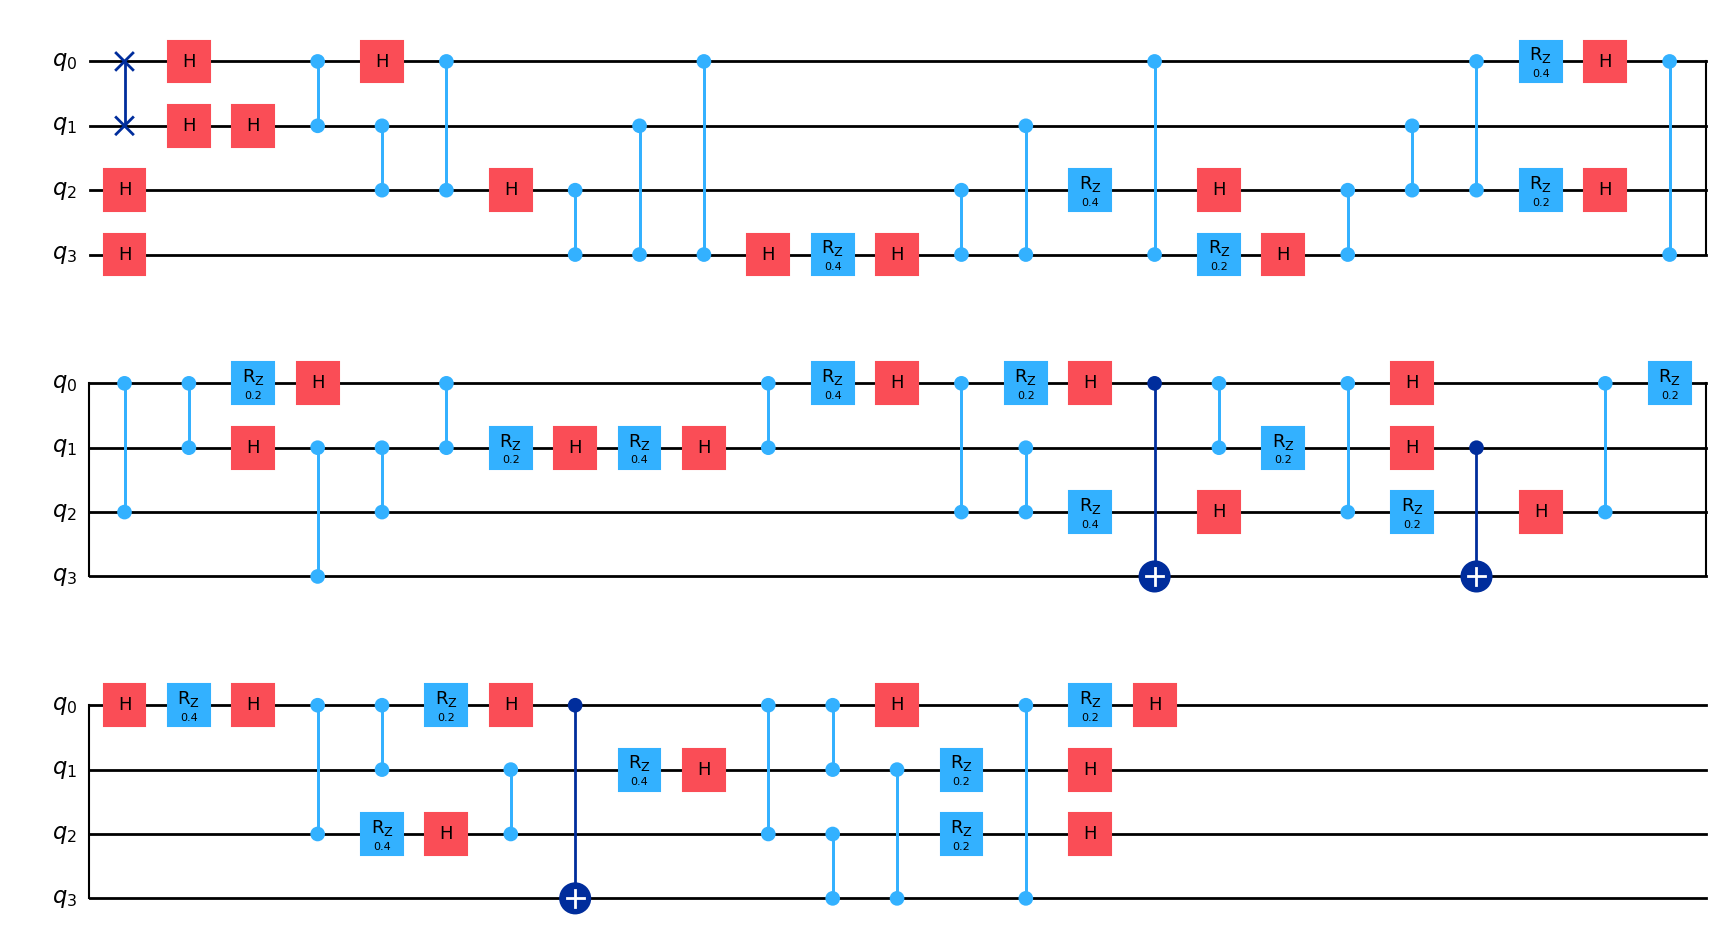

In [14]:
print("Baseline circuit:")
display(qc_baseline.draw("mpl"))

print("Careful (teleport_reduce) circuit:")
display(qc_careful.draw("mpl"))

print("Aggressive (full_reduce) circuit:")
display(qc_aggressive.draw("mpl"))

## 9. Comparison graphs: real vs. fake, across Total Gates, Two-Qubit Gates, T-Count, and Depth\n\nSame colorful bar-graph structure as the original pre-flight comparison, now split side-by-side for fake vs. real so both are visible in one figure — useful for a clean GitHub write-up.

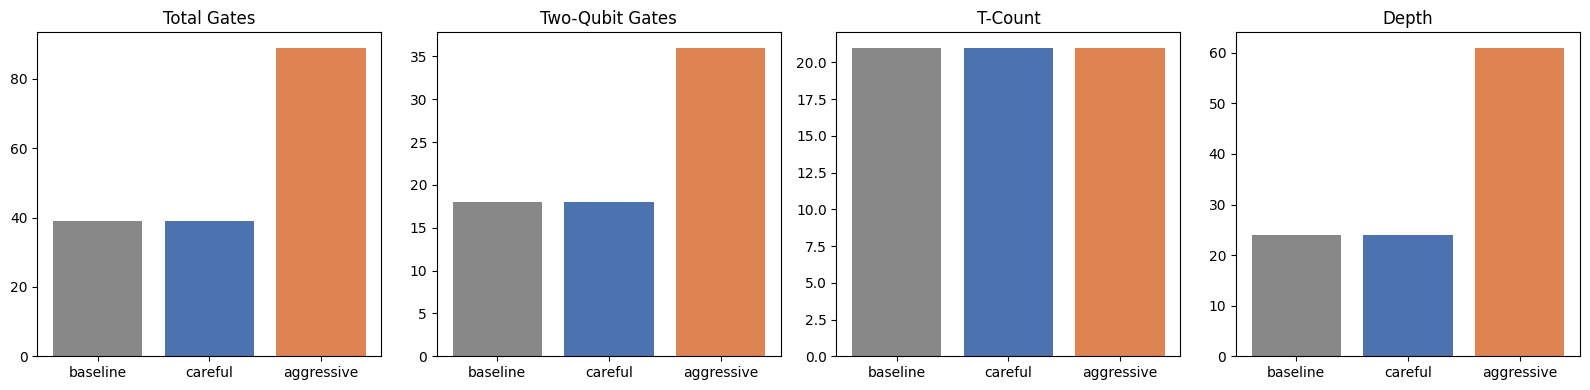

In [15]:
_names = list(versions.keys())
_metrics_list = [circuit_metrics(versions[n]) for n in _names]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, key, title in zip(
    axes,
    ["total_gates", "two_qubit_gates", "tcount", "depth"],
    ["Total Gates", "Two-Qubit Gates", "T-Count", "Depth"],
):
    values = [m[key] for m in _metrics_list]
    ax.bar(_names, values, color=["#888888", "#4C72B0", "#DD8452"])
    ax.set_title(title)
plt.tight_layout()
plt.show()

## Why did we see that?

---

| Method | What it optimizes for | Effect on my circuit | Why |
|---|---|---|---|
| **`full_reduce`** | spider count / T-count | ~3x gate blowup | Destroys the geometric locality my CNOT-cheapness depended on;<br>extraction (Gaussian elimination) pays for the added entanglement in CNOTs |
| **`teleport_reduce`** | merging matching phase gates only | no change vs. baseline | My circuit has no repeated matching phase angles for it to merge |

## 10. New accuracy metric: magnetization vs. exact answer

The old "all-zeros" accuracy mixed real physics with hardware noise: the transverse field is *supposed* to rotate qubits away from 0, so even a perfect machine would not score 100%.

- **Measured magnetization:** for each shot, a qubit measured as 0 counts +1 and a qubit measured as 1 counts -1. Average over all qubits and shots.
- **Exact magnetization:** the same quantity from a noiseless statevector simulation (the answer key).
- **Error = |measured - exact|.** Lower is better.

In [16]:
def measured_magnetization(counts, num_qubits):
    """Mean <Z> over all qubits, straight from measured counts.
    +1 for each '0' bit, -1 for each '1' bit, averaged over qubits and shots."""
    shots = sum(counts.values())
    total = 0.0
    for bitstring, c in counts.items():
        bits = bitstring.replace(" ", "")[-num_qubits:]
        total += sum(1 if b == "0" else -1 for b in bits) * c
    return total / (shots * num_qubits)

In [17]:
from qiskit.quantum_info import Statevector, SparsePauliOp

def exact_magnetization(circuit_no_measure, num_qubits):
    """Mean <Z> over all qubits from the noiseless statevector (the answer key).
    Pass a circuit with NO measurement instructions."""
    sv = Statevector.from_instruction(circuit_no_measure)
    vals = []
    for i in range(num_qubits):
        label = "I"*(num_qubits-1-i) + "Z" + "I"*i
        vals.append(sv.expectation_value(SparsePauliOp(label)).real)
    return sum(vals) / num_qubits

In [18]:
def build_versions_for(num_qubits, J=1.0, g=0.5, dt=0.2, steps=3):
    baseline = build_tfim_trotter_circuit(num_qubits, J, g, dt, steps)
    careful = teleport_reduce_circuit(baseline)
    aggressive = full_reduce_circuit(baseline)
    return {
        "baseline": baseline,
        "careful": careful,
        "aggressive": aggressive,
    }


### 10a. Scoring the 4-qubit runs (fake vs. real)

Rescores the counts already collected, so no new hardware runs. All three circuit versions are equivalent, so they share one exact answer.

exact magnetization (answer key) = 0.8645

baseline   fake: measured=0.6881 err=0.1764 | real: measured=0.5871 err=0.2774
careful    fake: measured=0.6907 err=0.1738 | real: measured=0.5769 err=0.2876
aggressive fake: measured=0.7772 err=0.0873 | real: measured=0.7874 err=0.0771


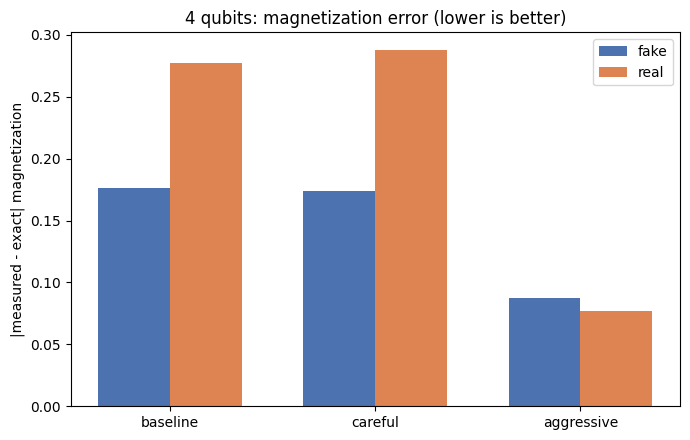

In [19]:
exact_4 = exact_magnetization(qc_baseline.remove_final_measurements(inplace=False), num_qubits)
print(f"exact magnetization (answer key) = {exact_4:.4f}\n")

fake_err_4, real_err_4 = [], []
for name in versions:
    m_fake = measured_magnetization(fake_results[name]["counts"], num_qubits)
    m_real = measured_magnetization(real_results[name]["counts"], num_qubits)
    fake_err_4.append(abs(m_fake - exact_4))
    real_err_4.append(abs(m_real - exact_4))
    print(f"{name:10s} fake: measured={m_fake:.4f} err={fake_err_4[-1]:.4f} | "
          f"real: measured={m_real:.4f} err={real_err_4[-1]:.4f}")

x = np.arange(len(versions))
width = 0.35
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(x - width/2, fake_err_4, width, label="fake", color="#4C72B0")
ax.bar(x + width/2, real_err_4, width, label="real", color="#DD8452")
ax.set_xticks(x)
ax.set_xticklabels(list(versions.keys()))
ax.set_ylabel("|measured - exact| magnetization")
ax.set_title(f"{num_qubits} qubits: magnetization error (lower is better)")
ax.legend()
plt.tight_layout()
plt.show()

## 11. Magnetization error vs. number of qubits

Repeats the comparison for larger circuits (fake backend only; set `RUN_REAL = True` to also run on real hardware, which uses IBM time). Fake runs are repeated `FAKE_REPS` times, so the plot shows mean ± standard deviation.


=== 5 qubits ===
exact magnetization (answer key) = 0.8688


/tmp/ipykernel_1109/2501373909.py:3: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)
/tmp/ipykernel_1109/2501373909.py:3: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client

baseline   fake: measured=0.7206 error=0.1482 +/- 0.0014
careful    fake: measured=0.7216 error=0.1472 +/- 0.0004
aggressive fake: measured=0.6825 error=0.1863 +/- 0.0080

=== 10 qubits ===
exact magnetization (answer key) = 0.8774


/tmp/ipykernel_1109/2501373909.py:3: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)
/tmp/ipykernel_1109/2501373909.py:3: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client

baseline   fake: measured=0.7631 error=0.1143 +/- 0.0040
careful    fake: measured=0.7609 error=0.1164 +/- 0.0025
aggressive fake: measured=0.2762 error=0.6012 +/- 0.0478


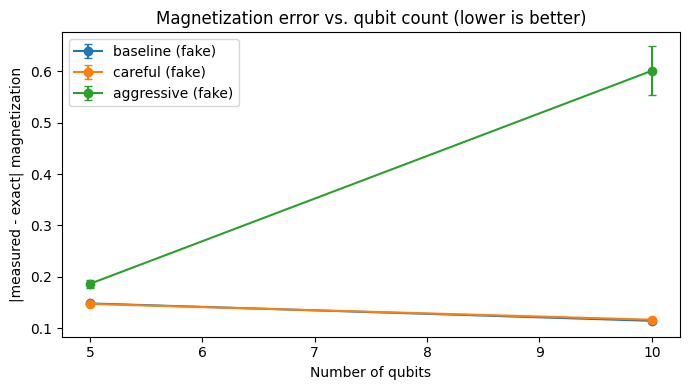

In [20]:
RUN_REAL = False            # keep False until fake results look right
QUBIT_COUNTS = [5, 10]      # add 15, 20 later (they can be slow)
FAKE_REPS = 3               # repeats on fake -> mean +/- std (free)
REAL_REPS = 1               # each real rep costs IBM time

fake_backend_multi = FakeKingston()
real_backend_multi = service.backend("ibm_kingston") if RUN_REAL else None

summary = {}

for nq in QUBIT_COUNTS:
    print(f"\n=== {nq} qubits ===")
    versions_nq = build_versions_for(nq, J, g, dt, steps)
    # the three versions are verified equal, so they share ONE answer key
    exact = exact_magnetization(versions_nq["baseline"].remove_final_measurements(inplace=False), nq)
    print(f"exact magnetization (answer key) = {exact:.4f}")
    summary[nq] = {}

    fake_errs = {n: [] for n in versions_nq}
    fake_meas = {n: [] for n in versions_nq}
    for _ in range(FAKE_REPS):
        res = run_versions_on_backend(versions_nq, fake_backend_multi, shots=shots_per_run)
        for n in versions_nq:
            m = measured_magnetization(res[n]["counts"], nq)
            fake_meas[n].append(m)
            fake_errs[n].append(abs(m - exact))

    real_errs = {n: [] for n in versions_nq}
    real_meas = {n: [] for n in versions_nq}
    if RUN_REAL:
        for _ in range(REAL_REPS):
            res = run_versions_on_backend(versions_nq, real_backend_multi, shots=shots_per_run)
            for n in versions_nq:
                m = measured_magnetization(res[n]["counts"], nq)
                real_meas[n].append(m)
                real_errs[n].append(abs(m - exact))
                print(f"  REAL job id ({nq}q, {n}): {res[n]['job_id']}")   # SAVE THESE

    for n in versions_nq:
        summary[nq][n] = {
            "fake_err": float(np.mean(fake_errs[n])),
            "fake_std": float(np.std(fake_errs[n])),
            "real_err": float(np.mean(real_errs[n])) if real_errs[n] else None,
        }
        s = summary[nq][n]
        line = (f"{n:10s} fake: measured={np.mean(fake_meas[n]):.4f} "
                f"error={s['fake_err']:.4f} +/- {s['fake_std']:.4f}")
        if s["real_err"] is not None:
            line += f" | real: measured={np.mean(real_meas[n]):.4f} error={s['real_err']:.4f}"
        print(line)

# error vs. number of qubits
fig, ax = plt.subplots(figsize=(7, 4))
for n in ["baseline", "careful", "aggressive"]:
    ax.errorbar(QUBIT_COUNTS,
                [summary[q][n]["fake_err"] for q in QUBIT_COUNTS],
                yerr=[summary[q][n]["fake_std"] for q in QUBIT_COUNTS],
                marker="o", capsize=3, label=f"{n} (fake)")
    if RUN_REAL:
        ax.plot(QUBIT_COUNTS, [summary[q][n]["real_err"] for q in QUBIT_COUNTS],
                marker="s", linestyle="--", label=f"{n} (real)")
ax.set_xlabel("Number of qubits")
ax.set_ylabel("|measured - exact| magnetization")
ax.set_title("Magnetization error vs. qubit count (lower is better)")
ax.legend()
plt.tight_layout()
plt.show()

### Results

- `baseline` and `careful` (teleport_reduce) give the same magnetization error within error bars, since teleport_reduce found nothing to merge in this circuit.
- `aggressive` (full_reduce) is noticeably worse, and the gap grows with qubit count (about 0.19 at 5 qubits and 0.60 at 10 on the fake backend). This is consistent with its roughly 3x gate count.
- Unlike the old all-zeros metric, this error does not collapse simply because there are more qubits.
- Caveat: these are noise-model (FakeKingston) results for this specific circuit; real-hardware results at these sizes have not been run.